# StreetCLIP Phase I – Setup and Test

This notebook loads everything both pairs need and checks that each part works.
Run it **top to bottom**. Every check prints a `PASS`, `WARN` or `FAIL` line; a summary is at the end.

1. Settings · 2. Environment · 3. Test-set download · 4. Pilot sample · 5. Candidate countries · 6. Metadata codes
7. StreetCLIP · 8. Crop modes · 9. Prediction table · 10. CLIP baseline · 11. Segmentation · 12. Text detection
13. Masking · 14. End-to-end · 15. Summary · 16. Shared baseline run (run once)

**Phase I rule:** the cached image embeddings are only for re-scoring. No embedding-space analysis in Phase I.

## 1. Settings

All shared settings with their defaults live in `Config` (`src/data.py`). Change them here, then run the rest.

In [21]:
import os, sys
from pathlib import Path

# Work from the repository root, so src/ can be imported and data/ + results/ land there
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch

from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector, Inpainter,
                        fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier

cfg = Config()

# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt


In [2]:
# Small helpers for this notebook: PASS/FAIL lines and image grids
results = []

def check(name, passed, detail="", warn_only=False):
    status = "PASS" if passed else ("WARN" if warn_only else "FAIL")
    results.append((status, name, detail))
    print(f"{status:4s} | {name}" + (f" | {detail}" if detail else ""))

def show_images(images, titles, cols=5, size=3.2):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, img, title in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.show()

## 2. Environment

In [3]:
print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()

check("GPU available", device == "cuda", detail=f"device = {device}", warn_only=True)

PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 5070
PASS | GPU available | device = cuda


## 3. Test-set download

Downloads `test.csv` (116 MB) and 5 zips (9.43 GB) only if they are missing, extracts them and deletes the zips.
Extraction briefly needs ~19 GB of free disk space.

In [4]:
mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper)
dataset.download()
dataset.load()

meta = dataset.meta
print(f"{len(meta):,} rows in test.csv | {meta['has_image'].sum():,} with an image file")
print("Example country labels:", meta["country"].drop_duplicates().head(10).tolist())

expected = ["id", "latitude", "longitude", "country", "region", "sub-region", "city", "land_cover",
            "road_index", "drive_side", "climate", "soil", "dist_sea", "captured_at", "sequence"]
missing_cols = [c for c in expected if c not in meta.columns]
check("test.csv has all expected columns", not missing_cols, detail=f"missing: {missing_cols}")
check("every row has an image file", meta["has_image"].all(),
      detail=f"{(~meta['has_image']).sum()} rows without image")

unmapped = dataset.unmapped_countries()
check("every country label is in country_aliases.csv", unmapped.empty,
      detail=f"unmapped: {unmapped.to_dict()}", warn_only=True)

210,122 rows in test.csv | 210,122 with an image file
Example country labels: ['MG', 'KZ', 'IT', 'ML', 'TH', 'SL', 'FR', 'MX', 'CI', 'JP']
PASS | test.csv has all expected columns | missing: []
PASS | every row has an image file | 0 rows without image
PASS | every country label is in country_aliases.csv | unmapped: {}


## 4. Pilot sample

Up to `images_per_country` images per country (fixed seed). Used for Q3 and quick checks; the main run (section 16) uses the full test set.

In [5]:
pilot_path = Path(cfg.resources_dir) / "pilot_ids.csv"
print("Pilot sample:", "loaded from" if pilot_path.exists() else "newly drawn and saved to", pilot_path)
pilot_ids = dataset.build_pilot()

counts = dataset.country_counts(pilot_ids)
print(f"{len(pilot_ids):,} pilot images from {len(counts)} countries "
      f"({counts['low_sample'].sum()} countries flagged low_sample)")
display(counts.sort_values("n_images").head(15))

missing = [i for i in pilot_ids if i not in dataset.image_paths]
check("all pilot images exist on this machine", not missing, detail=f"{len(missing)} missing")
check("shared pilot matches a fresh draw on this machine", pilot_ids == dataset.draw_pilot(),
      detail="if not: your data differs from the machine that created the file", warn_only=True)
check("no country above images_per_country", counts["n_images"].max() <= cfg.images_per_country)
check("low_sample flag matches counts",
      (counts["low_sample"] == (counts["n_images"] < cfg.images_per_country)).all())

Pilot sample: loaded from resources\pilot_ids.csv
9,578 pilot images from 219 countries (42 countries flagged low_sample)


,n_images,prompt_name,low_sample,in_candidates_v1,in_training_list
country_id,,,,,
SY,1,Syria,True,True,False
VA,2,Vatican City,True,False,False
AI,2,Anguilla,True,False,False
SX,3,Sint Maarten,True,False,False
MF,3,Saint Martin,True,False,False
MS,4,Montserrat,True,False,False
IM,6,Isle of Man,True,False,False
BH,7,Bahrain,True,True,False
GA,7,Gabon,True,True,False


PASS | all pilot images exist on this machine | 0 missing
PASS | shared pilot matches a fresh draw on this machine | if not: your data differs from the machine that created the file
PASS | no country above images_per_country
PASS | low_sample flag matches counts


## 5. Candidate countries

`v1` = the paper's 193 probing countries + 4 training-list territories (Bermuda, Guam, Monaco, Puerto Rico) = 197.
Images whose country is not a candidate are flagged `representable = False` and excluded from accuracy.

In [6]:
test_locations = dataset.test_locations()
candidates = mapper.candidates(cfg.candidate_list, test_locations)
prompts = mapper.prompts(candidates, cfg.prompt_template)
print(f"{len(candidates)} candidates ({cfg.candidate_list}); example prompt: {prompts[0]!r}")

not_candidates = [c for c in test_locations if c not in candidates]
n_not_repr = dataset.usable()["country_id"].isin(not_candidates).sum()
print(f"{len(not_candidates)} test locations are not candidates ({n_not_repr:,} images):",
      [mapper.prompt_name(c) for c in not_candidates])

if cfg.candidate_list == "v1":
    check("v1 has 197 candidates", len(candidates) == 197, detail=str(len(candidates)))
check("every candidate has a prompt name", all(isinstance(p, str) and p for p in prompts))

197 candidates (v1); example prompt: 'A Street View photo in Andorra, Southern Europe.'
31 test locations are not candidates (1,808 images): ['Anguilla', 'Åland Islands', 'Caribbean Netherlands', 'Curaçao', 'Christmas Island', 'Falkland Islands', 'Faroe Islands', 'French Guiana', 'Guernsey', 'Guadeloupe', 'Hong Kong', 'Isle of Man', 'Jersey', 'Kiribati', 'Cayman Islands', 'Saint Martin', 'Martinique', 'Montserrat', 'Maldives', 'New Caledonia', 'French Polynesia', 'Réunion', 'Svalbard and Jan Mayen', 'Sao Tome and Principe', 'Sint Maarten', 'Turks and Caicos Islands', 'Vatican City', 'British Virgin Islands', 'U.S. Virgin Islands', 'Kosovo', 'Mayotte']
PASS | v1 has 197 candidates | 197
PASS | every candidate has a prompt name


## 6. Metadata codes

The code tables in `MetadataDecoder` come from the sources OSV-5M names (Köppen-Geiger, FAO GLC-SHARE).
Their numbering in OSV-5M is not documented, so compare the codes that occur with the tables.

In [7]:
decoder = MetadataDecoder()

climate_codes = sorted(meta["climate"].dropna().unique())
land_codes = sorted(meta["land_cover"].dropna().unique())
print("climate codes in data:", climate_codes)
print("land_cover codes in data:", land_codes)

decoded = decoder.decode(meta[meta["country_id"].isin(["GB", "JP", "DE", "US"])])
sides = decoded.groupby("country_id")["drive_side_name"].agg(lambda s: set(s))
print(sides)
check("drive_side_name: GB and JP left, DE and US right (after fixes)", sides.get("GB") == {"left"} and sides.get("JP") == {"left"} and sides.get("DE") == {"right"} and sides.get("US") == {"right"})
check("climate codes within 0-30", min(climate_codes) >= 0 and max(climate_codes) <= 30, warn_only=True)
check("land_cover codes within 0-11 (else the numbering differs)",
      min(land_codes) >= 0 and max(land_codes) <= 11, detail=f"range {min(land_codes)}-{max(land_codes)}",
      warn_only=True)

climate codes in data: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]
land_cover codes in data: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
country_id
DE    {right}
GB     {left}
JP     {left}
US    {right}
Name: drive_side_name, dtype: object
PASS | drive_side_name: GB and JP left, DE and US right (after fixes)
PASS | climate codes within 0-30
PASS | land_cover codes within 0-11 (else the numbering differs) | range 0-11


## 7. StreetCLIP

First a reference test with the model card's own example (5 cities, no template), then predictions on 10 pilot images.

In [8]:
from huggingface_hub import hf_hub_download
from PIL import Image

model = GeoCLIPModel(cfg.streetclip_model, cfg)

# Reference test: same image and same choices as the StreetCLIP model card
sf_image = Image.open(hf_hub_download("geolocal/StreetCLIP", "sanfrancisco.jpeg")).convert("RGB")
cities = ["San Jose", "San Diego", "Los Angeles", "Las Vegas", "San Francisco"]
model.set_candidates(cities)
ref = model.predict([sf_image])
print("Model card example:", model.top_k(ref["probs"], k=5)[0])
check("reference image -> San Francisco", model.top_k(ref["probs"], k=1)[0][0][0] == "San Francisco")

W1106 10:35:51.744000 38284 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 590/590 [00:00<00:00, 5624.92it/s]


Model card example: [('San Francisco', 0.9697331786155701), ('San Jose', 0.028353122994303703), ('Los Angeles', 0.0011074155336245894), ('San Diego', 0.0007623701822012663), ('Las Vegas', 4.388455272419378e-05)]
PASS | reference image -> San Francisco


PASS | output shape = images x candidates | (10, 197)
PASS | probabilities sum to 1
PASS | no NaN in scores
PASS | embeddings have length 768


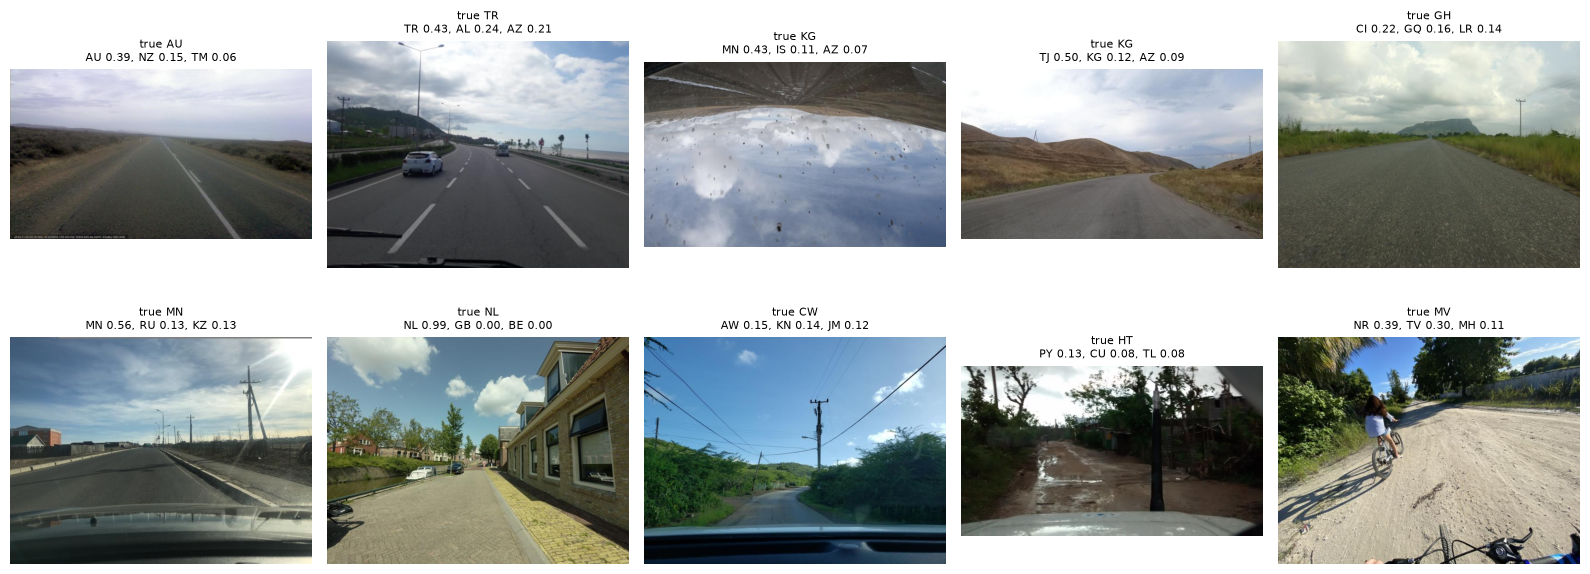

In [9]:
# Country candidates for everything that follows
model.set_candidates(candidates, prompts)

sample_ids = pilot_ids[:: max(1, len(pilot_ids) // 10)][:10]   # 10 images spread over countries
images = [dataset.get_image(i) for i in sample_ids]
out = model.predict(images)

check("output shape = images x candidates", out["probs"].shape == (10, len(candidates)),
      detail=str(out["probs"].shape))
check("probabilities sum to 1", np.allclose(out["probs"].sum(axis=1), 1, atol=1e-4))
check("no NaN in scores", not np.isnan(out["logits"]).any())
check("embeddings have length 768", out["embeddings"].shape[1] == 768)

titles = []
for image_id, top in zip(sample_ids, model.top_k(out["probs"], k=3)):
    true = meta.loc[image_id, "country_id"]
    guesses = ", ".join(f"{c} {p:.2f}" for c, p in top)
    titles.append(f"true {true}\n{guesses}")
show_images(images, titles)

## 8. Crop modes

What the model sees for one image under each mode. `center_crop` cuts the sides, `pad` keeps the whole image.

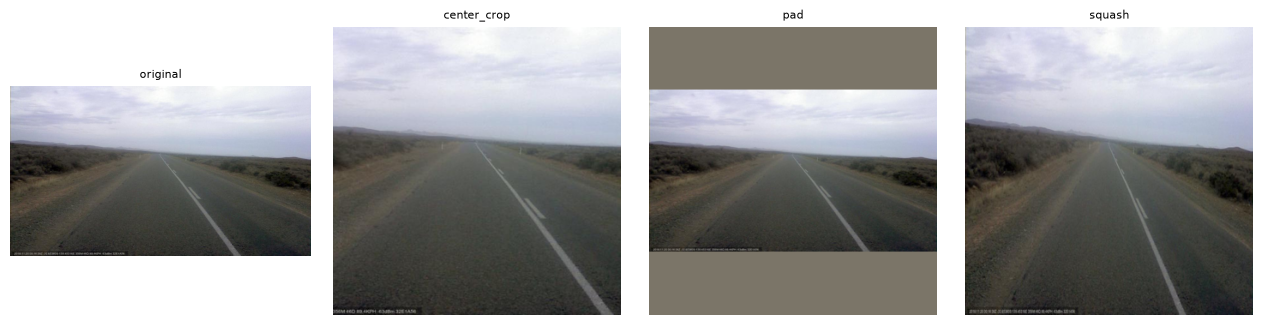

PASS | all crop modes give 336 x 336


In [10]:
image = images[0]
modes = ["center_crop", "pad", "squash"]
fitted = [fit_image(image, m) for m in modes]
show_images([image] + fitted, ["original"] + modes, cols=4)
check("all crop modes give 336 x 336", all(f.size == (336, 336) for f in fitted))

## 9. Prediction table

`PredictionRunner` on the 10 images, written to a throw-away test folder (not `results/shared/`).

In [11]:
runner = PredictionRunner(cfg, dataset, mapper)
test_dir = "results/_setup_test_run"
table = runner.run(model, sample_ids, run_name="setup_test", out_dir=test_dir, overwrite=True)
display(table.head(3))

reloaded, logits, embeds, info = PredictionRunner.load(test_dir)
check("table has one row per image", len(table) == 10)
check("saved logits shape", logits.shape == (10, len(candidates)))
check("saved embeddings shape", embeds.shape == (10, 768))
check("reloaded table has the same ids and predictions",
      reloaded["id"].tolist() == table["id"].tolist() and reloaded["pred_1"].tolist() == table["pred_1"].tolist())
check("runner gives the same top-1 as direct prediction",
      (logits.argmax(axis=1) == out["logits"].argmax(axis=1)).all())

setup_test: 100%|██████████| 1/1 [00:07<00:00,  7.10s/it]


,id,country_id,pred_1,prob_1,pred_2,prob_2,pred_3,prob_3,pred_4,prob_4,...,climate,soil,dist_sea,captured_at,sequence,model,crop_mode,candidate_list,prompt_template,variant
0,304083577920222,AU,AU,0.386797,NZ,0.148816,TM,0.063280,MN,0.048932,...,5,9,0.958045,1542712598000,EYATnIn_KJBZeGd2hJnqpA,geolocal/StreetCLIP,center_crop,v1,"A Street View photo in {country}, {subregion}.",original
1,211416763975529,TR,TR,0.432876,AL,0.241755,AZ,0.205931,MK,0.032427,...,0,14,0.014630,1557406320095,9dq5sdwm3w21h8ntzt6b1y,geolocal/StreetCLIP,center_crop,v1,"A Street View photo in {country}, {subregion}.",original
2,810649602910106,KG,MN,0.431764,IS,0.113366,AZ,0.071161,AM,0.065200,...,7,10,0.999995,1556276754000,6vdJ-vpMB_yeS6k4rkvhww,geolocal/StreetCLIP,center_crop,v1,"A Street View photo in {country}, {subregion}.",original


PASS | table has one row per image
PASS | saved logits shape
PASS | saved embeddings shape
PASS | reloaded table has the same ids and predictions
PASS | runner gives the same top-1 as direct prediction


## 10. CLIP baseline (only if `use_clip_baseline = True`)

In [12]:
if cfg.use_clip_baseline:
    clip_model = GeoCLIPModel(cfg.clip_model, cfg)
    clip_model.set_candidates(candidates, prompts)
    clip_out = clip_model.predict(images)
    check("CLIP output shape matches StreetCLIP", clip_out["probs"].shape == out["probs"].shape)
    del clip_model
    free_gpu_memory()
else:
    print("Skipped: use_clip_baseline = False")

Skipped: use_clip_baseline = False


## 11. Segmentation

Mask2Former (Mapillary Vistas). Check visually that the colours sit on road, sky, vegetation etc.

Loading weights: 100%|██████████| 758/758 [00:00<00:00, 1755.57it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch

PASS | all configured Vistas classes found | unmatched: []


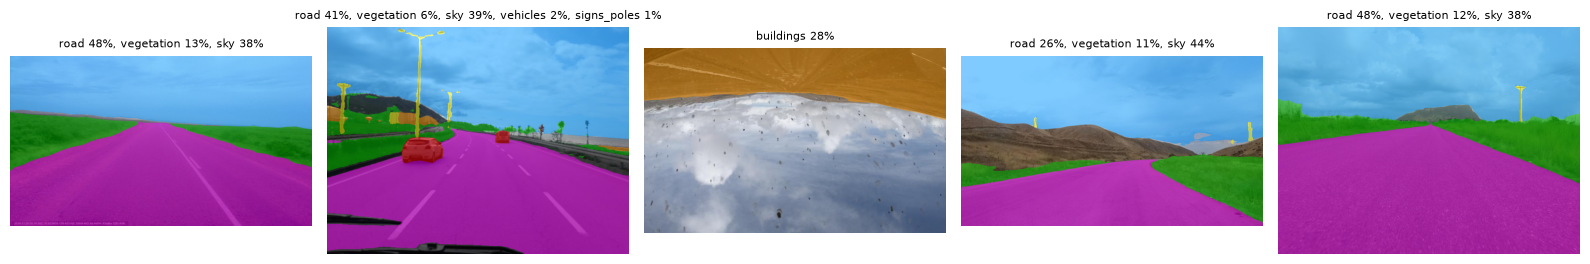

PASS | masks have the image size
PASS | masks are boolean


In [13]:
segmenter = Segmenter(cfg)
check("all configured Vistas classes found", not segmenter.unmatched,
      detail=f"unmatched: {segmenter.unmatched}", warn_only=True)

colours = {"road": (255, 0, 255), "vegetation": (0, 200, 0), "sky": (0, 150, 255),
           "buildings": (255, 150, 0), "vehicles": (255, 0, 0), "signs_poles": (255, 255, 0)}
overlays, titles, all_masks = [], [], {}
for image_id, image in zip(sample_ids[:5], images[:5]):
    masks = segmenter.element_masks(image, image_id)
    all_masks[image_id] = masks
    overlay = np.array(image).copy()
    for element, mask in masks.items():
        overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array(colours[element])).astype(np.uint8)
    overlays.append(overlay)
    titles.append(", ".join(f"{e} {m.mean():.0%}" for e, m in masks.items() if m.mean() > 0.01))

show_images(overlays, titles)
first = all_masks[sample_ids[0]]
check("masks have the image size", all(m.shape == images[0].size[::-1] for m in first.values()))
check("masks are boolean", all(m.dtype == bool for m in first.values()))

## 12. Text detection

Detection only (no recognition filter). Images from countries with non-Latin scripts are picked on purpose,
to see whether their text is found with the `["en"]` setting.

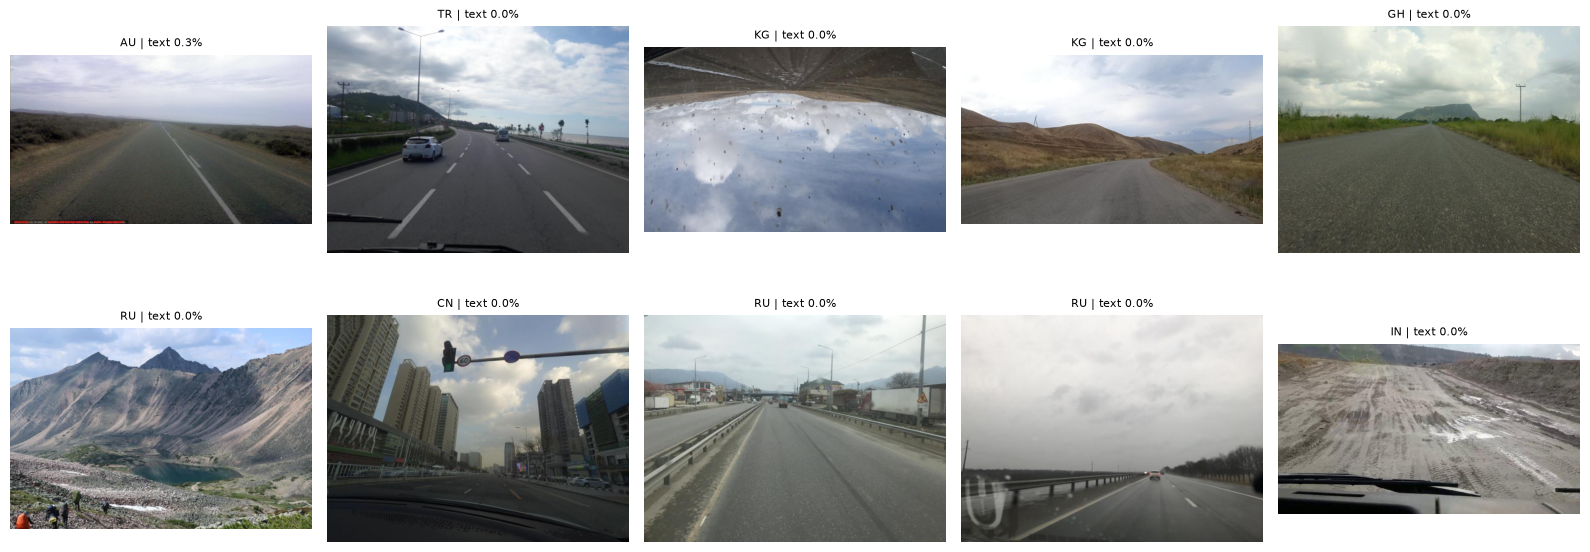

PASS | text found in at least one image | 1/10 images


In [14]:
detector = TextDetector(cfg)

script_countries = ["RU", "TH", "JP", "KR", "GR", "IL", "CN", "IN", "UA", "BG"]
script_ids = [i for i in pilot_ids if meta.loc[i, "country_id"] in script_countries][::10][:5]
text_ids = sample_ids[:5] + script_ids

boxed, titles, n_with_text = [], [], 0
for image_id in text_ids:
    image = dataset.get_image(image_id)
    mask = detector.text_mask(image, image_id)
    n_with_text += mask.any()
    shown = np.array(image).copy()
    shown[mask] = (0.4 * shown[mask] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
    boxed.append(shown)
    titles.append(f"{meta.loc[image_id, 'country_id']} | text {mask.mean():.1%}")

show_images(boxed, titles)
check("text found in at least one image", n_with_text > 0, detail=f"{n_with_text}/{len(text_ids)} images")

## 13. Masking

One image, one element: original, gray, blur, inpaint (only if `fill_mode = "inpaint"`) and a random control.

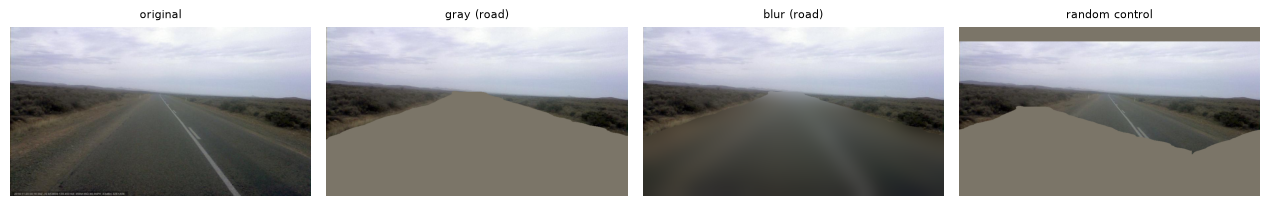

road: 47.9% of the full image, 55.0% of what the model sees
PASS | gray fill changes only masked pixels
PASS | dilation grows the mask
PASS | random control has the same area
PASS | tiny mask is skipped and logged
PASS | edge strip outside the center crop is not counted as visible | full image 2.2%, visible 0.0%


In [15]:
inpainter = Inpainter(cfg) if cfg.fill_mode == "inpaint" else None
applier = MaskApplier(cfg, inpainter)

image_id, image = sample_ids[0], images[0]
masks = all_masks[image_id]
element = max(["road", "vegetation", "buildings"], key=lambda e: masks[e].mean())  # biggest one
raw = masks[element]

result = applier.apply(image, raw, element, image_id)
used = result["mask"]
gray = applier.fill(image, used, "gray")
blur = applier.fill(image, used, "blur")
controls = applier.apply_controls(image, used, n=1)

shown = [image, gray, blur, controls[0]["image"]]
titles = ["original", f"gray ({element})", f"blur ({element})", "random control"]
if inpainter:
    shown.insert(3, applier.fill(image, used, "inpaint"))
    titles.insert(3, f"inpaint ({element})")
show_images(shown, titles, cols=len(shown))
print(f"{element}: {raw.mean():.1%} of the full image, {result['visible_fraction']:.1%} of what the model sees")

changed = np.any(np.array(gray) != np.array(image), axis=2)
check("gray fill changes only masked pixels", not changed[~used].any())
check("dilation grows the mask", used.sum() > raw.sum() or cfg.mask_dilation_px == 0)
check("random control has the same area", controls[0]["mask"].sum() == used.sum())

tiny = np.zeros_like(raw)
tiny[:3, :3] = True
check("tiny mask is skipped and logged",
      applier.apply(image, tiny, "road", "tiny-test")["image"] is None and len(applier.skipped_log()) > 0)

edge = np.zeros_like(raw)
if raw.shape[1] >= raw.shape[0]:
    edge[:, :20] = True   # landscape image: strip at the left edge
else:
    edge[:20, :] = True   # portrait image: strip at the top edge
check("edge strip outside the center crop is not counted as visible",
      cfg.crop_mode != "center_crop" or applier.visible_fraction(edge) < edge.mean(),
      detail=f"full image {edge.mean():.1%}, visible {applier.visible_fraction(edge):.1%}")

## 14. End-to-end: original vs. masked prediction

true country: AU
original                     | masked (road)
AU   0.391                   | EC   0.064
NZ   0.151                   | CV   0.050
TM   0.062                   | NI   0.047
MN   0.048                   | KE   0.027
IR   0.039                   | SO   0.027


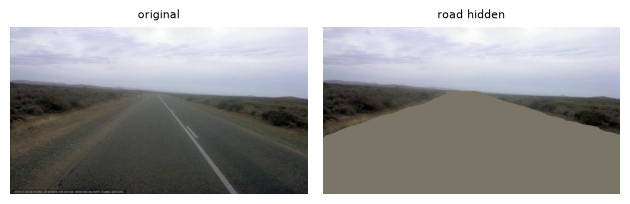

PASS | masked image gives valid predictions


In [16]:
masked_image = result["image"] if result["image"] is not None else gray
both = model.predict([image, masked_image])
top_original, top_masked = model.top_k(both["probs"], k=5)

print("true country:", meta.loc[image_id, "country_id"])
print(f"{'original':28s} | masked ({element})")
for (c1, p1), (c2, p2) in zip(top_original, top_masked):
    print(f"{c1:4s} {p1:.3f}{'':18s} | {c2:4s} {p2:.3f}")
show_images([image, masked_image], ["original", f"{element} hidden"], cols=2)
check("masked image gives valid predictions", np.allclose(both["probs"].sum(axis=1), 1, atol=1e-4))

## 15. Summary

In [17]:
if torch.cuda.is_available():
    peak_gb = torch.cuda.max_memory_allocated() / 1e9
    check("peak GPU memory under 12 GB", peak_gb < 12, detail=f"{peak_gb:.1f} GB")

n_fail = sum(s == "FAIL" for s, _, _ in results)
n_warn = sum(s == "WARN" for s, _, _ in results)
print(f"\n{len(results)} checks: {len(results) - n_fail - n_warn} PASS, {n_warn} WARN, {n_fail} FAIL")
for status, name, detail in results:
    if status != "PASS":
        print(f"  {status} {name} {detail}")

PASS | peak GPU memory under 12 GB | 1.9 GB

35 checks: 35 PASS, 0 WARN, 0 FAIL


## 16. Shared baseline run (run once)

The main StreetCLIP run over the **full test set** (~210k images, under an hour on an RTX 5070).
It writes `results/shared/<run_name>/` and refuses to overwrite it afterwards: this is the read-only baseline
both pairs start from. Set the flags to `True` once all checks above pass.

In [22]:
RUN_STREETCLIP_MAIN = True # Set tot true
RUN_CLIP_MAIN = False          # needs use_clip_baseline = True

run_suffix = f"{cfg.candidate_list}_{cfg.crop_mode}"
all_ids = dataset.all_ids()

if RUN_STREETCLIP_MAIN:
    runner.run(model, all_ids, run_name=f"streetclip_{run_suffix}")

if RUN_CLIP_MAIN and cfg.use_clip_baseline:
    del model
    free_gpu_memory()
    clip_model = GeoCLIPModel(cfg.clip_model, cfg)
    clip_model.set_candidates(candidates, prompts)
    runner.run(clip_model, all_ids, run_name=f"clip_{run_suffix}")

streetclip_v1_center_crop: 100%|██████████| 6567/6567 [32:46<00:00,  3.34it/s]


**Changing the candidate list later** (e.g. the sensitivity run with `all_test_locations`) does not need the
images again: `runner.rescore(source_run, model, new_run_name)` re-scores the cached embeddings with the
model's current candidates. Use the same model and crop mode that produced the source run.